In [1]:
import quarters_clean

In [2]:
credit_q_df = quarters_clean.pd.read_parquet("../data/quarter_private_credit_values.parquet")

In [4]:
credit_q_df.tail()

,Austria,Philippines,Year,Month,Quarter
112,334.12,8503.83,2020,None,4
113,360.17,8891.59,2021,None,4
114,381.32,10265.97,2022,None,4
115,379.59,11142.73,2023,None,4
116,379.19,12551.07,2024,None,4


In [9]:
credit_q_df.head()

,Austria,Philippines,Year,Quarter
0,133.25,NaN,1996,1
1,142.70,NaN,1997,1
2,152.34,NaN,1998,1
3,160.72,NaN,1999,1
4,174.30,NaN,2000,1


In [5]:
quarters_clean.summarize_missing_by_country(credit_q_df)

,Missing Count,Missing %
Month,117,100.00
Philippines,52,44.44
Austria,0,0.00


**H1)** The previous output indicates that Philippines will be the country that will most restrict us in the time range available to perform the correlation analysis. This statement is only correct due to the process of extracting and joining the values of this indicator. If indicators were downloaded for a country and those values were not available for a time range already existing in the master data frame, NaN values were assigned.

In [6]:
credit_q_df = credit_q_df.drop(columns=["Month"])

In [7]:
missing_entries = quarters_clean.get_missing_entries(credit_q_df)
missing_entries.head()

,Quarter,Year,Country,Value
0,1,1996,Philippines,NaN
1,1,1997,Philippines,NaN
2,1,1998,Philippines,NaN
3,1,1999,Philippines,NaN
4,1,2000,Philippines,NaN


In [8]:
philippines_missing = quarters_clean.clean_country_missing_entries(missing_entries, "Philippines")
philippines_missing

,Quarter,Year,Country,Value
0,1,1996,Philippines,NaN
1,2,1996,Philippines,NaN
2,3,1996,Philippines,NaN
3,4,1996,Philippines,NaN
4,1,1997,Philippines,NaN
5,2,1997,Philippines,NaN
6,3,1997,Philippines,NaN
7,4,1997,Philippines,NaN
8,1,1998,Philippines,NaN
9,2,1998,Philippines,NaN


The previous outputs show us that Philippines has no values for the private credit index from 1996 to 2008. Consequently, it has values in the range from 2009 to 2024, a desirable range since other values which we extracted with the crawlers are defined between 2014 and 2023.

### Let's delete all the data from the beginning until 2011

In [10]:
clean_df1 = credit_q_df.copy()

In [11]:
clean_df1 = quarters_clean.filter_by_year(clean_df1, min_year=2008, max_year=2024)
clean_df1

,Austria,Philippines,Year,Quarter
0,255.51,1836.97,2009,1
1,255.40,1936.69,2010,1
2,262.12,2240.12,2011,1
3,271.60,2638.67,2012,1
4,272.12,2958.98,2013,1
...,...,...,...,...
59,334.12,8503.83,2020,4
60,360.17,8891.59,2021,4
61,381.32,10265.97,2022,4
62,379.59,11142.73,2023,4


In [12]:
clean_df1 = clean_df1.sort_values(by=['Year', 'Quarter'])
clean_df1

,Austria,Philippines,Year,Quarter
0,255.51,1836.97,2009,1
16,254.35,1858.55,2009,2
32,255.15,1864.56,2009,3
48,254.29,1972.77,2009,4
1,255.40,1936.69,2010,1
...,...,...,...,...
62,379.59,11142.73,2023,4
15,378.13,11220.41,2024,1
31,379.18,11526.48,2024,2
47,379.95,11839.43,2024,3


In [13]:
quarters_clean.summarize_missing_by_country(clean_df1)

,Missing Count,Missing %
Austria,0,0.0
Philippines,0,0.0


In [14]:
clean_df1 = clean_df1.reset_index(drop=True)
clean_df1

,Austria,Philippines,Year,Quarter
0,255.51,1836.97,2009,1
1,254.35,1858.55,2009,2
2,255.15,1864.56,2009,3
3,254.29,1972.77,2009,4
4,255.40,1936.69,2010,1
...,...,...,...,...
59,379.59,11142.73,2023,4
60,378.13,11220.41,2024,1
61,379.18,11526.48,2024,2
62,379.95,11839.43,2024,3


In [15]:
clean_df1 = quarters_clean.average_by_year(clean_df1)

   Year  Austria  Philippines
0  2009  254.825    1883.2125
1  2010  260.335    2046.4300
2  2011  267.745    2442.4700
3  2012  273.450    2793.2950
4  2013  273.135    3183.3175


### For month values now

In [16]:
credit_m_df = quarters_clean.pd.read_parquet("../data/month_private_credit_values.parquet")

In [17]:
credit_m_df.head()

,Australia,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1965,Apr,2.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1966,Apr,2.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1967,Apr,2.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1968,Apr,2.0
4,NaN,NaN,NaN,NaN,76.62,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1969,Apr,2.0


In [18]:
credit_m_df.tail()

,Australia,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,Cyprus,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
719,2656.79,337.54,3816.70,59.95,5227.54,182947.95,167170.64,491135.59,29.30,29.01,...,6815.09,1222.74,18795.54,2763.79,8935.90,1950.39,102957.00,2020,Sep,3.0
720,2798.94,360.76,4438.82,64.34,5604.59,192524.37,186973.00,522911.25,29.94,27.07,...,7156.31,1273.02,19614.18,3123.79,8717.06,2000.95,115220.50,2021,Sep,3.0
721,3045.09,392.50,5162.92,72.76,6056.00,216732.78,207689.24,612999.30,33.26,25.94,...,7806.13,1314.64,20315.16,5171.32,9704.41,2087.93,129783.89,2022,Sep,3.0
722,3208.11,401.25,5614.67,80.19,6264.30,222143.82,229391.60,646816.89,35.82,23.04,...,8002.97,1336.51,20489.53,8176.98,10142.10,2097.03,142860.38,2023,Sep,3.0
723,3382.14,406.20,6216.18,91.19,6442.77,226636.56,246962.72,652364.66,38.59,23.03,...,7968.71,1357.65,20531.97,11550.68,10304.61,2108.30,166684.36,2024,Sep,3.0


In [19]:
quarters_clean.summarize_missing_by_country(credit_m_df)

,Missing Count,Missing %
New-Zealand,621,85.77
China,598,82.60
Japan,576,79.56
India,563,77.76
Croatia,558,77.07
Greece,543,75.00
Indonesia,541,74.72
Poland,528,72.93
Russia,519,71.69
Romania,505,69.75


In [20]:
credit_m_df.shape

(724, 59)

**H1)** The previous output indicates that New-Zealand will be the country that will most restrict us in the time range available to perform the correlation analysis. This statement is only correct due to the process of extracting and joining the values of this indicator. If indicators were downloaded for a country and those values were not available for a time range already existing in the master data frame, NaN values were assigned.

In [21]:
credit_m_df = credit_m_df.drop(columns=["Month"])

In [23]:
missing_entries = quarters_clean.get_missing_entries(credit_m_df)
missing_entries.head()

,Quarter,Year,Country,Value
0,1.0,1965,Australia,NaN
1,1.0,1965,Belgium,NaN
2,1.0,1965,Brazil,NaN
3,1.0,1965,Bulgaria,NaN
4,1.0,1965,Canada,NaN


In [24]:
new_zealand_missing = quarters_clean.clean_country_missing_entries(missing_entries, "New-Zealand")
new_zealand_missing

,Quarter,Year,Country,Value
0,1.0,1965,New-Zealand,NaN
1,2.0,1965,New-Zealand,NaN
2,2.0,1965,New-Zealand,NaN
3,2.0,1965,New-Zealand,NaN
4,3.0,1965,New-Zealand,NaN
...,...,...,...,...
616,3.0,2016,New-Zealand,NaN
617,3.0,2016,New-Zealand,NaN
618,3.0,2016,New-Zealand,NaN
619,4.0,2016,New-Zealand,NaN


In [26]:
new_zealand_missing[new_zealand_missing['Year'] == 2016]

,Quarter,Year,Country,Value
610,1.0,2016,New-Zealand,NaN
611,1.0,2016,New-Zealand,NaN
612,1.0,2016,New-Zealand,NaN
613,2.0,2016,New-Zealand,NaN
614,2.0,2016,New-Zealand,NaN
615,2.0,2016,New-Zealand,NaN
616,3.0,2016,New-Zealand,NaN
617,3.0,2016,New-Zealand,NaN
618,3.0,2016,New-Zealand,NaN
619,4.0,2016,New-Zealand,NaN


In [41]:
credit_m_df.loc[credit_m_df['Year'] == 2010, ['Year', 'New-Zealand']]

,Year,New-Zealand
45,2010,NaN
106,2010,NaN
166,2010,NaN
225,2010,NaN
285,2010,NaN
346,2010,NaN
406,2010,NaN
467,2010,NaN
528,2010,NaN
589,2010,NaN


The previous outputs show us that New-Zealand has no values for the private credit index from 1965 to 2016. Consequently, it has values in the range from 2016 to 2024, not a desirable range since other values which we extracted with the crawlers are defined between 2014 and 2023. For that reason we gonna make a foward fill from 2014

### Let's delete all the data from the beginning until 2014

In [42]:
clean_df2 = credit_m_df.copy()

In [43]:
clean_df2 = quarters_clean.filter_by_year(clean_df2, min_year=2013, max_year=2024)
clean_df2

,Australia,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,Cyprus,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Quarter
0,2026.96,225.04,2771.35,54.37,3573.31,107989.39,NaN,286835.91,29.49,52.93,...,1348.32,4848.05,1019.60,14214.29,913.13,6361.71,1583.85,51613.65,2014,2.0
1,2167.40,238.45,3070.71,49.02,3784.61,118082.62,87907.74,325414.04,29.25,51.14,...,1269.29,5109.37,1038.56,14979.18,1144.37,6761.44,1608.00,64951.57,2015,2.0
2,2337.59,254.77,3150.82,48.07,3948.24,130706.01,98863.72,369773.22,27.43,48.55,...,1218.21,5398.98,1056.65,15595.84,1272.81,7276.37,1667.78,71220.04,2016,2.0
3,2466.34,267.91,3082.41,49.92,4267.84,139886.67,111120.36,395686.66,27.07,44.73,...,1191.50,5752.77,1086.17,16156.78,1554.01,7594.67,1730.76,71613.27,2017,2.0
4,2579.67,294.26,3103.64,52.60,4545.66,148413.40,124669.66,417596.86,27.14,40.08,...,1153.33,6114.72,1121.99,17084.85,1830.84,7955.68,1805.59,78400.73,2018,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,2656.79,337.54,3816.70,59.95,5227.54,182947.95,167170.64,491135.59,29.30,29.01,...,1157.14,6815.09,1222.74,18795.54,2763.79,8935.90,1950.39,102957.00,2020,3.0
128,2798.94,360.76,4438.82,64.34,5604.59,192524.37,186973.00,522911.25,29.94,27.07,...,1150.17,7156.31,1273.02,19614.18,3123.79,8717.06,2000.95,115220.50,2021,3.0
129,3045.09,392.50,5162.92,72.76,6056.00,216732.78,207689.24,612999.30,33.26,25.94,...,1163.57,7806.13,1314.64,20315.16,5171.32,9704.41,2087.93,129783.89,2022,3.0
130,3208.11,401.25,5614.67,80.19,6264.30,222143.82,229391.60,646816.89,35.82,23.04,...,1122.96,8002.97,1336.51,20489.53,8176.98,10142.10,2097.03,142860.38,2023,3.0


In [44]:
quarters_clean.summarize_missing_by_country(clean_df2)

,Missing Count,Missing %
New-Zealand,35,26.52
China,12,9.09
Finland,7,5.30
France,6,4.55
Croatia,3,2.27
Portugal,3,2.27
Latvia,3,2.27
Colombia,3,2.27
Slovenia,2,1.52
Chile,0,0.00


In [45]:
clean_df2["New-Zealand"] = clean_df2["New-Zealand"].ffill()
clean_df2["China"] = clean_df2["China"].ffill()
clean_df2["Finland"] = clean_df2["Finland"].ffill()
clean_df2["France"] = clean_df2["France"].ffill()
clean_df2["Croatia"] = clean_df2["Croatia"].ffill()
clean_df2["Portugal"] = clean_df2["Portugal"].ffill()
clean_df2["Latvia"] = clean_df2["Latvia"].ffill()
clean_df2["Colombia"] = clean_df2["Colombia"].ffill()
clean_df2["Slovenia"] = clean_df2["Slovenia"].ffill()

In [47]:
clean_df2["New-Zealand"] = clean_df2["New-Zealand"].bfill()
clean_df2["China"] = clean_df2["China"].bfill()

In [48]:
quarters_clean.summarize_missing_by_country(clean_df2)

,Missing Count,Missing %
Australia,0,0.0
Belgium,0,0.0
Brazil,0,0.0
Bulgaria,0,0.0
Canada,0,0.0
Chile,0,0.0
China,0,0.0
Colombia,0,0.0
Croatia,0,0.0
Cyprus,0,0.0


In [49]:
clean_df2.head()

,Australia,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,Cyprus,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Quarter
0,2026.96,225.04,2771.35,54.37,3573.31,107989.39,87907.74,286835.91,29.49,52.93,...,1348.32,4848.05,1019.60,14214.29,913.13,6361.71,1583.85,51613.65,2014,2.0
1,2167.40,238.45,3070.71,49.02,3784.61,118082.62,87907.74,325414.04,29.25,51.14,...,1269.29,5109.37,1038.56,14979.18,1144.37,6761.44,1608.00,64951.57,2015,2.0
2,2337.59,254.77,3150.82,48.07,3948.24,130706.01,98863.72,369773.22,27.43,48.55,...,1218.21,5398.98,1056.65,15595.84,1272.81,7276.37,1667.78,71220.04,2016,2.0
3,2466.34,267.91,3082.41,49.92,4267.84,139886.67,111120.36,395686.66,27.07,44.73,...,1191.50,5752.77,1086.17,16156.78,1554.01,7594.67,1730.76,71613.27,2017,2.0
4,2579.67,294.26,3103.64,52.60,4545.66,148413.40,124669.66,417596.86,27.14,40.08,...,1153.33,6114.72,1121.99,17084.85,1830.84,7955.68,1805.59,78400.73,2018,2.0


In [50]:
clean_df2 = clean_df2.sort_values(by=['Year', 'Quarter'])
clean_df2

,Australia,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,Cyprus,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Quarter
33,2009.01,218.74,2725.65,53.76,3530.56,107265.98,248442.98,279803.42,29.53,53.84,...,1364.24,4794.60,1011.11,14141.63,904.86,6295.92,1588.22,50488.39,2014,1.0
44,1997.73,219.98,2713.27,53.49,3513.31,106767.07,237837.49,276364.03,29.58,54.12,...,1378.07,4776.71,1008.20,14116.87,904.09,6264.29,1587.01,51484.99,2014,1.0
77,2017.38,219.77,2752.29,54.03,3554.41,107314.13,244257.50,282404.01,29.56,53.39,...,1355.26,4810.83,1014.15,14188.83,909.31,6317.22,1584.26,51043.82,2014,1.0
0,2026.96,225.04,2771.35,54.37,3573.31,107989.39,87907.74,286835.91,29.49,52.93,...,1348.32,4848.05,1019.60,14214.29,913.13,6361.71,1583.85,51613.65,2014,2.0
66,2059.14,225.63,2824.63,54.64,3606.35,109540.58,244086.17,295360.82,29.22,52.81,...,1339.28,4910.08,1025.45,14323.72,944.84,6440.83,1588.55,52819.46,2014,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,3342.61,414.02,6065.27,89.47,6404.02,226149.19,244086.17,651557.89,38.24,23.11,...,1122.67,7958.65,1353.93,20533.88,10903.81,10284.96,2094.27,158999.53,2024,3.0
131,3382.14,406.20,6216.18,91.19,6442.77,226636.56,246962.72,652364.66,38.59,23.03,...,1119.27,7968.71,1357.65,20531.97,11550.68,10304.61,2108.30,166684.36,2024,3.0
32,3440.53,412.35,6461.23,94.95,6520.03,233732.18,248442.98,645066.63,36.38,23.45,...,1126.01,7986.12,1364.98,20628.47,12344.50,10380.41,2125.43,176189.16,2024,4.0
109,3423.47,409.68,6365.58,93.95,6517.41,231178.61,247718.20,647259.03,36.25,22.88,...,1133.16,7993.84,1364.50,20547.23,11923.17,10333.81,2122.48,172875.18,2024,4.0


In [51]:
clean_df2 = clean_df2.reset_index(drop=True)
clean_df2

,Australia,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,Cyprus,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Quarter
0,2009.01,218.74,2725.65,53.76,3530.56,107265.98,248442.98,279803.42,29.53,53.84,...,1364.24,4794.60,1011.11,14141.63,904.86,6295.92,1588.22,50488.39,2014,1.0
1,1997.73,219.98,2713.27,53.49,3513.31,106767.07,237837.49,276364.03,29.58,54.12,...,1378.07,4776.71,1008.20,14116.87,904.09,6264.29,1587.01,51484.99,2014,1.0
2,2017.38,219.77,2752.29,54.03,3554.41,107314.13,244257.50,282404.01,29.56,53.39,...,1355.26,4810.83,1014.15,14188.83,909.31,6317.22,1584.26,51043.82,2014,1.0
3,2026.96,225.04,2771.35,54.37,3573.31,107989.39,87907.74,286835.91,29.49,52.93,...,1348.32,4848.05,1019.60,14214.29,913.13,6361.71,1583.85,51613.65,2014,2.0
4,2059.14,225.63,2824.63,54.64,3606.35,109540.58,244086.17,295360.82,29.22,52.81,...,1339.28,4910.08,1025.45,14323.72,944.84,6440.83,1588.55,52819.46,2014,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,3342.61,414.02,6065.27,89.47,6404.02,226149.19,244086.17,651557.89,38.24,23.11,...,1122.67,7958.65,1353.93,20533.88,10903.81,10284.96,2094.27,158999.53,2024,3.0
128,3382.14,406.20,6216.18,91.19,6442.77,226636.56,246962.72,652364.66,38.59,23.03,...,1119.27,7968.71,1357.65,20531.97,11550.68,10304.61,2108.30,166684.36,2024,3.0
129,3440.53,412.35,6461.23,94.95,6520.03,233732.18,248442.98,645066.63,36.38,23.45,...,1126.01,7986.12,1364.98,20628.47,12344.50,10380.41,2125.43,176189.16,2024,4.0
130,3423.47,409.68,6365.58,93.95,6517.41,231178.61,247718.20,647259.03,36.25,22.88,...,1133.16,7993.84,1364.50,20547.23,11923.17,10333.81,2122.48,172875.18,2024,4.0


In [52]:
clean_df2 = quarters_clean.average_by_year(clean_df2)

   Year    Australia     Belgium       Brazil   Bulgaria       Canada  \
0  2014  2059.295833  225.752500  2838.650000  53.499167  3625.665000   
1  2015  2207.458333  242.079167  3118.230000  48.985000  3831.788333   
2  2016  2367.798333  257.061667  3144.354167  48.569167  4018.940833   
3  2017  2493.594167  272.460000  3079.704167  50.203333  4328.751667   
4  2018  2550.039167  296.660000  3145.520833  53.060833  4598.107500   

           Chile          China       Colombia    Croatia  ...  South-Africa  \
0  110597.641667  230344.822500  295285.935833  29.307500  ...   2564.023333   
1  121668.064167   89968.404167  338351.788333  28.923333  ...   2769.898333   
2  132957.866667  101082.665833  376920.004167  27.235000  ...   2958.854167   
3  140648.523333  113768.913333  400657.728333  26.863333  ...   3121.054167   
4  151849.870833  127878.274167  422649.320000  27.257500  ...   3266.100000   

    South-Korea        Spain       Sweden  Switzerland      Thailand  \
0  1.656

In [53]:
clean_df2

,Year,Australia,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
0,2014,2059.295833,225.752500,2838.650000,53.499167,3625.665000,110597.641667,230344.822500,295285.935833,29.307500,...,2564.023333,1.656976e+06,1329.992500,4904.642500,1023.036667,14370.266667,956.303333,6439.305833,1594.228333,54563.191667
1,2015,2207.458333,242.079167,3118.230000,48.985000,3831.788333,121668.064167,89968.404167,338351.788333,28.923333,...,2769.898333,1.772220e+06,1255.991667,5169.620833,1042.725833,15106.401667,1179.131667,6858.948333,1618.274167,67513.942500
2,2016,2367.798333,257.061667,3144.354167,48.569167,4018.940833,132957.866667,101082.665833,376920.004167,27.235000,...,2958.854167,1.905550e+06,1210.711667,5480.584167,1063.621667,15736.673333,1325.750833,7375.714167,1684.606667,71808.759167
3,2017,2493.594167,272.460000,3079.704167,50.203333,4328.751667,140648.523333,113768.913333,400657.728333,26.863333,...,3121.054167,2.040886e+06,1182.984167,5818.697500,1092.934167,16368.619167,1604.715000,7675.154167,1734.642500,73508.770000
4,2018,2550.039167,296.660000,3145.520833,53.060833,4598.107500,151849.870833,127878.274167,422649.320000,27.257500,...,3266.100000,2.177151e+06,1155.023333,6185.662500,1128.425833,17305.496667,1897.358333,8017.707500,1811.995000,82234.815000
5,2019,2589.645000,312.139167,3324.501667,56.615833,4868.058333,165626.949167,144024.678333,454326.414167,28.071667,...,3474.825000,2.321115e+06,1138.136667,6496.670000,1168.330833,18043.513333,1972.800000,8395.480000,1873.763333,93416.321667
6,2020,2656.729167,336.944167,3699.682500,59.558333,5142.110000,180922.465000,162797.725000,490306.972500,29.311667,...,3569.215000,2.547467e+06,1151.945000,6775.467500,1215.022500,18687.370000,2543.676667,8913.593333,1936.857500,101165.776667
7,2021,2760.232500,355.418333,4293.584167,63.393333,5503.575833,189016.830833,182748.101667,511957.184167,29.945833,...,3638.675833,2.820613e+06,1154.720000,7084.244167,1263.140833,19449.630833,3094.935833,8758.148333,1985.519167,112769.130000
8,2022,2991.540000,385.760833,4997.425833,70.780833,5950.617500,210598.787500,202841.207500,591743.935000,32.309167,...,3923.561667,3.088564e+06,1162.745833,7670.883333,1306.094167,20182.210833,4754.577500,9472.405833,2058.680000,127254.085000
9,2023,3173.511667,400.703333,5524.423333,78.350000,6209.459167,220842.305833,224770.925000,642305.567500,35.151667,...,4204.555833,3.203576e+06,1133.153333,7978.570833,1330.610000,20419.525833,7490.907500,10112.509167,2088.522500,139338.302500


In [54]:
clean_df1

,Year,Austria,Philippines
0,2009,254.8250,1883.2125
1,2010,260.3350,2046.4300
2,2011,267.7450,2442.4700
3,2012,273.4500,2793.2950
4,2013,273.1350,3183.3175
5,2014,273.5900,3759.7600
6,2015,274.8325,4407.8050
7,2016,280.1000,5056.6325
8,2017,286.6575,6057.2675
9,2018,298.1300,7136.6325


In [57]:
df_merged = quarters_clean.pd.merge(clean_df1, clean_df2, on='Year', how='inner')
df_merged

,Year,Austria,Philippines,Australia,Belgium,Brazil,Bulgaria,Canada,Chile,China,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
0,2014,273.5900,3759.7600,2059.295833,225.752500,2838.650000,53.499167,3625.665000,110597.641667,230344.822500,...,2564.023333,1.656976e+06,1329.992500,4904.642500,1023.036667,14370.266667,956.303333,6439.305833,1594.228333,54563.191667
1,2015,274.8325,4407.8050,2207.458333,242.079167,3118.230000,48.985000,3831.788333,121668.064167,89968.404167,...,2769.898333,1.772220e+06,1255.991667,5169.620833,1042.725833,15106.401667,1179.131667,6858.948333,1618.274167,67513.942500
2,2016,280.1000,5056.6325,2367.798333,257.061667,3144.354167,48.569167,4018.940833,132957.866667,101082.665833,...,2958.854167,1.905550e+06,1210.711667,5480.584167,1063.621667,15736.673333,1325.750833,7375.714167,1684.606667,71808.759167
3,2017,286.6575,6057.2675,2493.594167,272.460000,3079.704167,50.203333,4328.751667,140648.523333,113768.913333,...,3121.054167,2.040886e+06,1182.984167,5818.697500,1092.934167,16368.619167,1604.715000,7675.154167,1734.642500,73508.770000
4,2018,298.1300,7136.6325,2550.039167,296.660000,3145.520833,53.060833,4598.107500,151849.870833,127878.274167,...,3266.100000,2.177151e+06,1155.023333,6185.662500,1128.425833,17305.496667,1897.358333,8017.707500,1811.995000,82234.815000
5,2019,315.7025,7893.0700,2589.645000,312.139167,3324.501667,56.615833,4868.058333,165626.949167,144024.678333,...,3474.825000,2.321115e+06,1138.136667,6496.670000,1168.330833,18043.513333,1972.800000,8395.480000,1873.763333,93416.321667
6,2020,330.5200,8487.9425,2656.729167,336.944167,3699.682500,59.558333,5142.110000,180922.465000,162797.725000,...,3569.215000,2.547467e+06,1151.945000,6775.467500,1215.022500,18687.370000,2543.676667,8913.593333,1936.857500,101165.776667
7,2021,348.0075,8562.6225,2760.232500,355.418333,4293.584167,63.393333,5503.575833,189016.830833,182748.101667,...,3638.675833,2.820613e+06,1154.720000,7084.244167,1263.140833,19449.630833,3094.935833,8758.148333,1985.519167,112769.130000
8,2022,375.0325,9747.2650,2991.540000,385.760833,4997.425833,70.780833,5950.617500,210598.787500,202841.207500,...,3923.561667,3.088564e+06,1162.745833,7670.883333,1306.094167,20182.210833,4754.577500,9472.405833,2058.680000,127254.085000
9,2023,381.3100,10535.5550,3173.511667,400.703333,5524.423333,78.350000,6209.459167,220842.305833,224770.925000,...,4204.555833,3.203576e+06,1133.153333,7978.570833,1330.610000,20419.525833,7490.907500,10112.509167,2088.522500,139338.302500


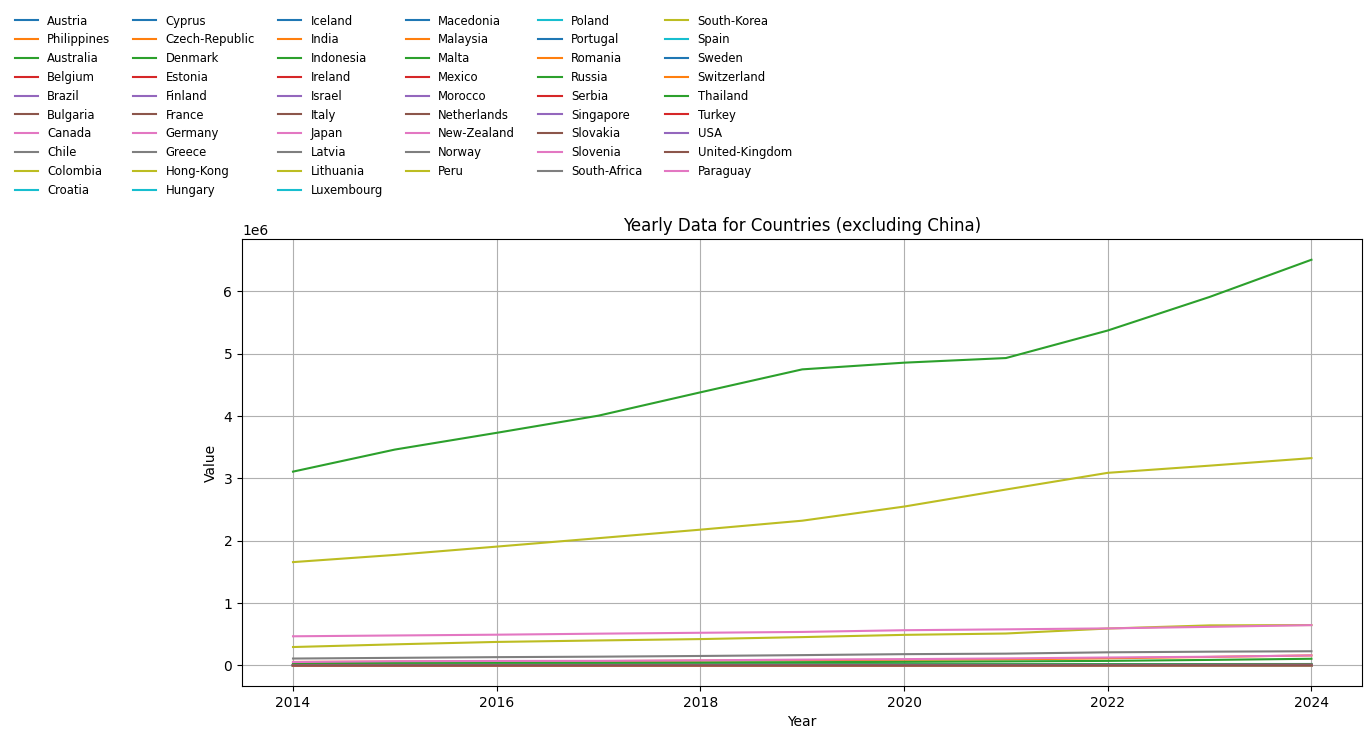

In [58]:
quarters_clean.plot_countries(df_merged, exclude_country='China', legend_columns=6)

In [59]:
df_merged.to_parquet("../data/clean_private_credit_index.parquet", index=False)